# Qismet: from a pruning score to an IBM quantum circuit

**Real IBM hardware experiment completed. See the hardware evidence in section 6 and Hardware_Results.md.**

The existing classifier receives 784 image pixels and predicts ten clothing classes.
Eight mask bits each retain/remove two hidden neurons. We keep exactly four groups in
this first hardware experiment. The 4-percentage-point tolerance is assessed on validation
accuracy; final test results do not choose the mask.

The quantum circuit proposes masks. PyTorch trains the neural networks on the CPU.
Follow these cells in order, then use README.md to configure IBM access locally.


In [1]:
from pathlib import Path
import json, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from circuit_core import *
from workflow import problem_and_warmstart, PROTOCOL
BASE=Path('.').resolve()
problem,initial_angles,prior=problem_and_warmstart()
display(pd.DataFrame([{'group':i,'neurons':f'{2*i}, {2*i+1}','linear coefficient':problem.linear[i]} for i in range(8)]))
print('Mask bit 1 keeps the group; bit 0 removes it.')


,group,neurons,linear coefficient
0,0,"0, 1",-0.231115
1,1,"2, 3",-0.022020
2,2,"4, 5",-0.275534
3,3,"6, 7",-0.300348
4,4,"8, 9",-0.308983
5,5,"10, 11",-0.281971
6,6,"12, 13",-0.251661
7,7,"14, 15",-0.243145


Mask bit 1 keeps the group; bit 0 removes it.


## 1. Define the expensive objective and its approximation

$g(m)=L_{val}(Train(W_0\text{ restricted by }m))$ requires retraining.
The frozen quadratic approximation is
$f(m)=c+\sum_i a_i m_i+\sum_{i<j}b_{ij}m_i m_j$.
This initial hardware run reuses the original fitted coefficients; it does not improve the surrogate.
Earlier mean held-out R² was negative, so we cannot call the approximation accurate in absolute loss.


,pruning,model,mae_mean,r2_mean,spearman_mean,selection_regret_mean,selected_val_loss_mean,audit_masks_per_seed
0,50.0,Linear,0.051235,-7.026229,0.574454,0.012071,0.553771,35
1,50.0,Quadratic,0.035743,-3.465325,0.571765,0.018915,0.560616,35
2,75.0,Linear,0.088209,0.166348,0.757363,0.022079,0.666269,14
3,75.0,Quadratic,0.114416,-0.741589,0.736264,0.011569,0.655759,14


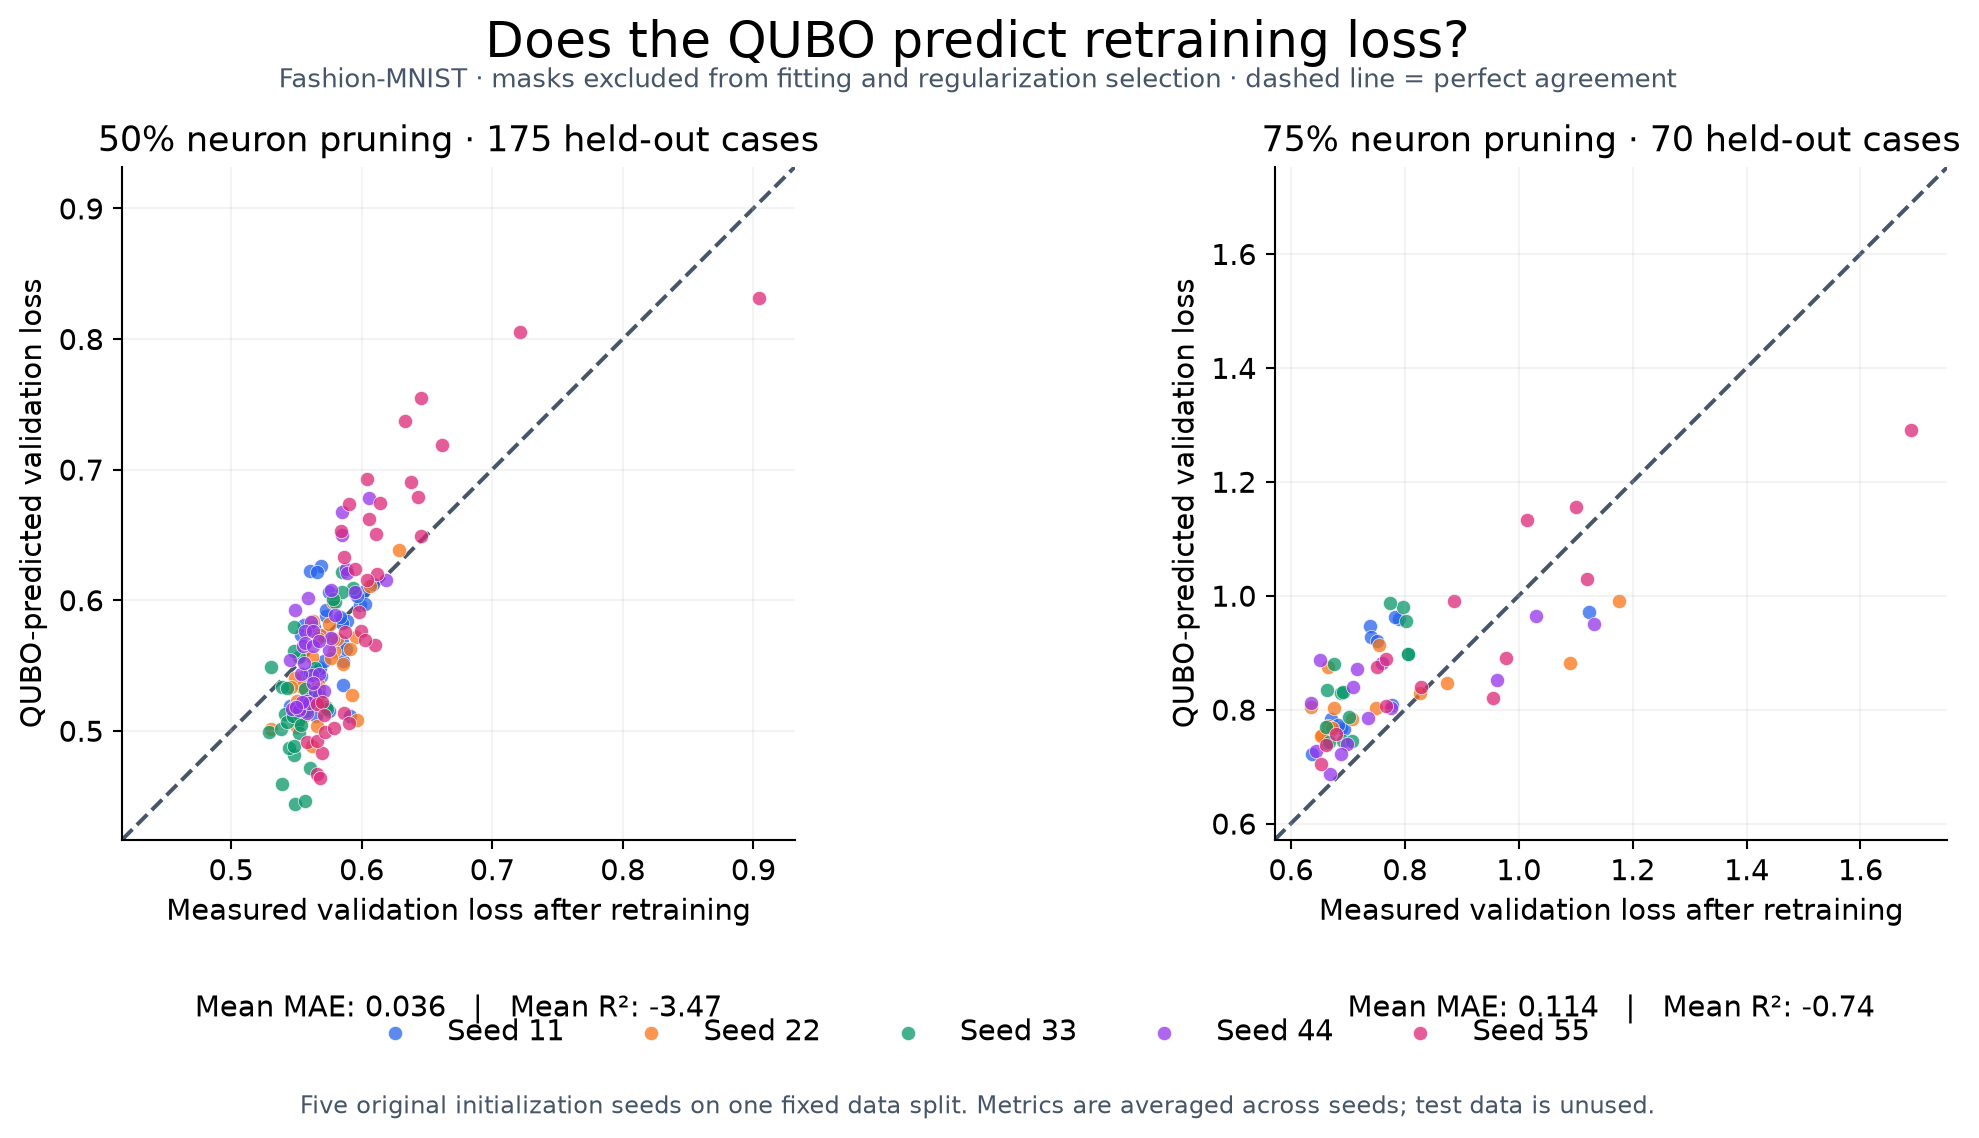

In [2]:
audit=pd.read_csv(BASE.parent/'fashion_v2'/'surrogate_summary.csv')
display(audit)
display(Image(filename=str(BASE.parent/'fashion_v2'/'approximation_check'/'qubo_loss_fidelity.png')))


## 2. Encode a cost exactly

Add $\lambda(\sum m_i-4)^2$ for the required group count and replace $m_i$ by $(I-Z_i)/2$.
The resulting diagonal operator satisfies $H_C|m\rangle=C(m)|m\rangle$.
This is exact algebra, not another learned approximation. Energy scaling only changes how angles
are expressed; the constant offset contributes a global phase and is omitted from circuit gates.

The following three-bit example is small enough to check by hand. Enumeration here is a diagnostic;
hardware scoring evaluates only observed bitstrings.


In [3]:
toy=toy_data()
display(pd.DataFrame(toy['basis_table']))
print(qubo_to_ising(toy_problem()))
print('Actual eight-bit Ising operator:')
print(qubo_to_ising(problem))


,bitstring_q2q1q0,mask_m0m1m2,surrogate,penalized_cost,feasible
0,000,"[0, 0, 0]",0.4,21.6,False
1,001,"[1, 0, 0]",-0.8,4.5,False
2,010,"[0, 1, 0]",-0.3,5.0,False
3,011,"[1, 1, 0]",-0.7,-0.7,True
4,100,"[0, 0, 1]",-0.5,4.8,False
5,101,"[1, 0, 1]",-1.4,-1.4,True
6,110,"[0, 1, 1]",-1.6,-1.6,True
7,111,"[1, 1, 1]",-1.7,3.6,False


SparsePauliOp(['III', 'IIZ', 'IZI', 'ZII', 'IZZ', 'ZIZ', 'ZZI'],
              coeffs=[4.475+0.j, 2.975+0.j, 2.9  +0.j, 3.125+0.j, 2.85 +0.j, 2.725+0.j,
 2.55 +0.j])
Actual eight-bit Ising operator:
SparsePauliOp(['IIIIIIII', 'IIIIIIIZ', 'IIIIIIZI', 'IIIIIZII', 'IIIIZIII', 'IIIZIIII', 'IIZIIIII', 'IZIIIIII', 'ZIIIIIII', 'IIIIIIZZ', 'IIIIIZIZ', 'IIIIZIIZ', 'IIIZIIIZ', 'IIZIIIIZ', 'IZIIIIIZ', 'ZIIIIIIZ', 'IIIIIZZI', 'IIIIZIZI', 'IIIZIIZI', 'IIZIIIZI', 'IZIIIIZI', 'ZIIIIIZI', 'IIIIZZII', 'IIIZIZII', 'IIZIIZII', 'IZIIIZII', 'ZIIIIZII', 'IIIZZIII', 'IIZIZIII', 'IZIIZIII', 'ZIIIZIII', 'IIZZIIII', 'IZIZIIII', 'ZIIZIIII', 'IZZIIIII', 'ZIZIIIII', 'ZZIIIIII'],
              coeffs=[9.38530561+0.j, 0.03153877+0.j, 0.01661986+0.j, 0.04239909+0.j,
 0.04444427+0.j, 0.03867113+0.j, 0.0390678 +0.j, 0.03543854+0.j,
 0.03796467+0.j, 2.18911088+0.j, 2.2143831 +0.j, 2.20750029+0.j,
 2.20814126+0.j, 2.20071259+0.j, 2.20573615+0.j, 2.20499058+0.j,
 2.18320259+0.j, 2.19564276+0.j, 2.19589783+0.j, 2.19587821+

## 3. Build the QAOA circuit

The Hadamard layer prepares a superposition. Each cost layer uses RZ and RZZ gates determined
by the Ising coefficients. RX gates implement the X mixer. Two repetitions use four classical
angle parameters. Cost evolution changes phases; subsequent mixing can change measured probabilities.

The code printed below is the actual circuit builder used by this package. The first diagram is
a three-qubit teaching example; the second is the actual eight-variable pruning circuit.


def build_qaoa(problem, reps=2, measure=False, barriers=False):
    """Build standard X-mixer QAOA with ParameterVector('gamma'/'beta').

    Start with H on every qubit. Each layer applies the diagonal cost phase,
    then RX(2*beta) on every qubit, i.e. exp(-i*beta*sum(X)).
    When measured, exactly one classical register named 'mask' is created;
    use result.data.mask.get_counts() with Runtime SamplerV2. An unmeasured
    circuit has no classical registers. Barrier insertion is for diagrams only.
    """
    if isinstance(reps, bool) or int(reps) != reps or reps < 1:
        raise ValueError("reps must be a positive integer")
    reps = int(reps)
    gamma, beta = ParameterVector("gamma", reps), ParameterVector("beta", reps)
    q = QuantumRegister(problem.n, "q")
    qc = QuantumCircuit(q, name=f"Qismet_QAOA_p{reps}")
    qc.h(range(problem.n))
    if barriers:
        qc.barrier(label="initial |+>")
    for layer in range(reps):
        qc.compose(cost_layer(problem, gamma[laye

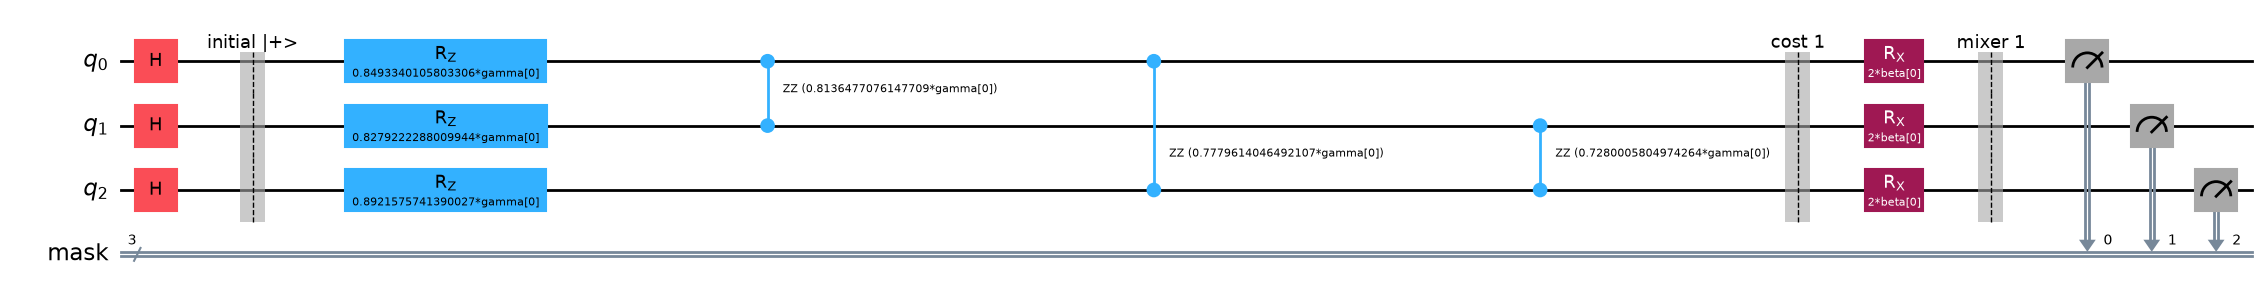

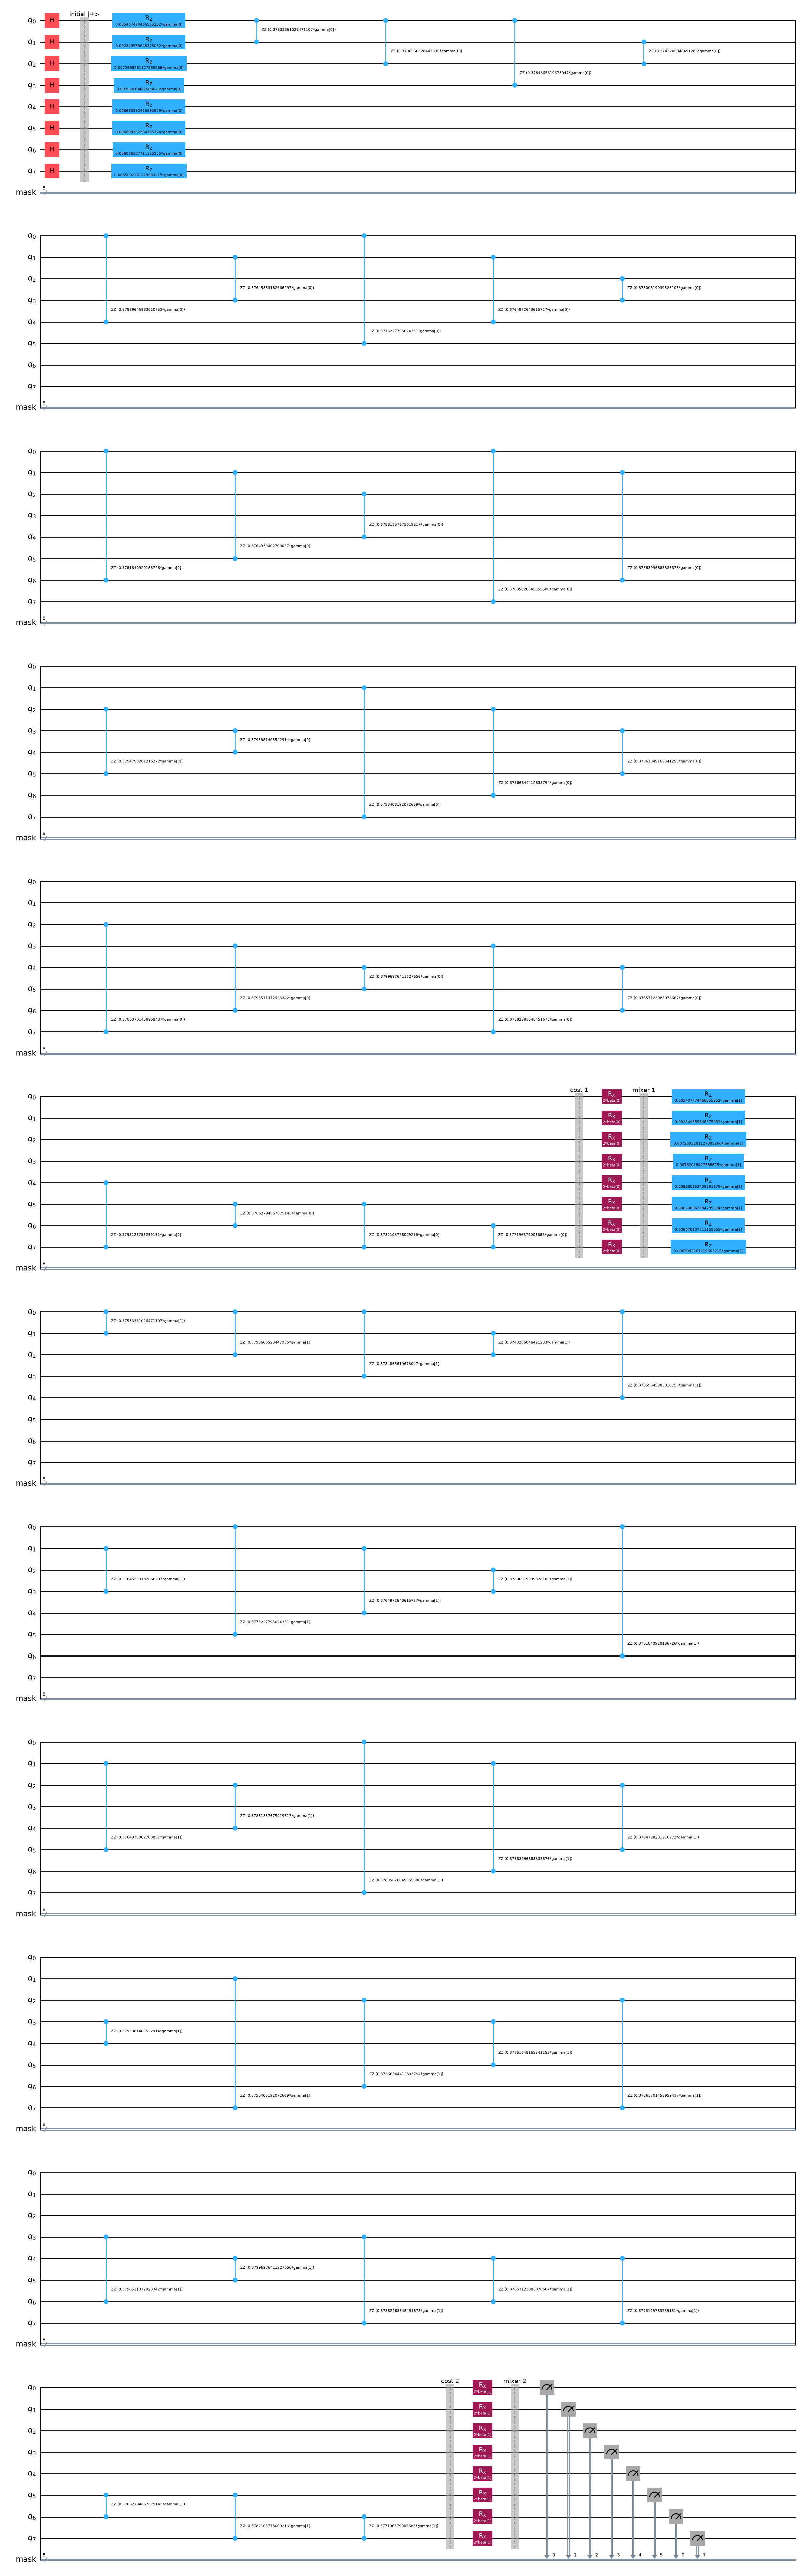

In [4]:
print(inspect.getsource(build_qaoa))
for name,p,reps in [('teaching_circuit',toy_problem(),1),('pruning_circuit',problem,2)]:
    qc=build_qaoa(p,reps=reps,measure=True,barriers=True)
    fig=qc.draw(output='mpl',fold=35)
    fig.savefig(BASE/(name+'.png'),dpi=130,bbox_inches='tight')
    display(fig); plt.close(fig)


## 4. Verify that the refactor preserves the original experiment

Gamma/beta binding order and little-endian mask interpretation are easy sources of errors.
Here the old saved probability vector and the newly built circuit must agree.


In [5]:
probabilities=ideal_probabilities(problem,initial_angles,reps=2)
error=np.max(np.abs(probabilities-np.array(prior['probabilities'])))
assert error<1e-12
print('Maximum probability difference:',error)
print('PASS: the new circuit reproduces the original saved Qiskit simulation.')


Maximum probability difference: 3.2959746043559335e-17
PASS: the new circuit reproduces the original saved Qiskit simulation.


## 5. Understand the measured-cost feedback loop

The classical optimizer sends angles to the circuit. Measurements return masks, whose costs
are computed classically. Their average estimates the circuit's expected cost.

This budgeted run uses three SPSA steps. Each step evaluates two angle perturbations,
estimates a gradient, then updates the angles. It starts from the saved simulator-optimized
angles. The best *observed* parameter setting gets a separate final measurement.
Three updates are a demonstration budget, not evidence of convergence or superiority.

The executed outputs below are an ideal finite-shot rehearsal of the same control flow.
They are explicitly not hardware results.


In [6]:
state=json.loads((BASE/'runs'/'dry-run'/'state.json').read_text())
assert state['mode']=='dry-run' and state['complete']
trace=pd.DataFrame([{'phase':h['phase'],'iteration':h['iteration'],'scaled mean cost':h['scaled_mean_cost'],
                    'shots':h['shots'],'feasible fraction':h['stats']['feasible_fraction']} for h in state['history']])
display(trace)
print('Dry-run selected mask:',state['selected_mask'])
print('Final selection uses 32 observed shots; the full 2048 estimate the distribution.')
display(pd.read_csv(BASE/'runs'/'dry-run'/'final_comparison.csv'))


,phase,iteration,scaled mean cost,shots,feasible fraction
0,replay,0,-0.625586,1024,0.690430
1,plus,0,-0.495676,1024,0.512695
2,minus,0,-0.514314,1024,0.542969
3,plus,1,-0.484230,1024,0.470703
4,minus,1,-0.452450,1024,0.627930
5,plus,2,-0.456472,1024,0.450195
6,minus,2,-0.527293,1024,0.623047
7,final,3,-0.627096,2048,0.676758


Dry-run selected mask: [0, 0, 1, 1, 1, 0, 1, 0]
Final selection uses 32 observed shots; the full 2048 estimate the distribution.


,mode,method,mask_state,parameters,retraining_seconds,val_loss,val_accuracy,test_loss,test_accuracy,inference_batch_1_ms,inference_batch_32_ms,validation_drop_pp,meets_4pp_target
0,dry-run,Dense,255,12730,1.999001,0.520531,0.823,0.507138,0.8233,0.063123,0.078334,0.000000,True
1,dry-run,QAOA selected,92,6370,1.227562,0.552084,0.813,0.543899,0.8147,0.046422,0.098307,0.999999,True
2,dry-run,Exact QUBO,60,6370,1.442217,0.536211,0.819,0.535312,0.8181,0.054542,0.092736,0.400001,True
3,dry-run,Best of 32 random,60,6370,1.717117,0.536211,0.819,0.535312,0.8181,0.046345,0.089033,0.400001,True


### How close does QAOA get to the QUBO optimum?

This is a separate question from whether the QUBO predicts retrained loss.
For this small diagnostic only, enumerate the 70 masks retaining four groups.
Compare their exact QUBO costs with the selected mask's cost. A zero gap means
the QUBO optimum was found; it does not mean the true retraining optimum was found.
The probability graph conditions on feasible outcomes; infeasible shots still cost resources.


,exact feasible QUBO minimum,selected QUBO cost,selected cost gap,ideal feasible probability
0,0.510974,0.514004,0.003031,0.681797


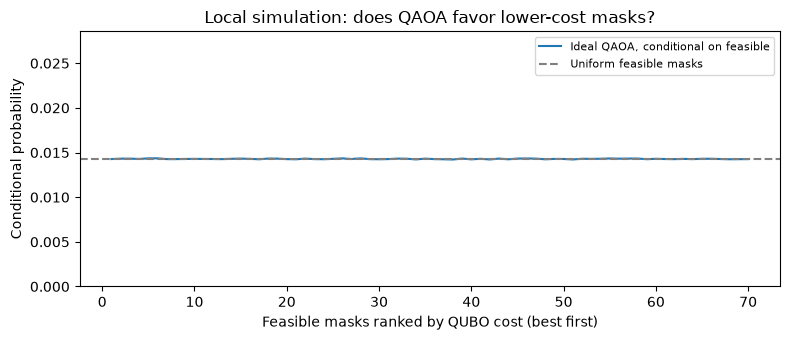

Only a future hardware run can provide hardware probabilities and job timings.


In [7]:
masks=np.array([[(i>>j)&1 for j in range(8)] for i in range(256)])
feasible=np.flatnonzero(masks.sum(axis=1)==4)
values=np.array([cost(problem,masks[i],penalized=False) for i in feasible])
order=np.argsort(values)
final_angles=state['history'][-1]['parameters']
p_final=ideal_probabilities(problem,final_angles,reps=2)
mass=float(p_final[feasible].sum())
selected_value=cost(problem,state['selected_mask'],penalized=False)
display(pd.DataFrame([{'exact feasible QUBO minimum':values.min(),
                      'selected QUBO cost':selected_value,
                      'selected cost gap':selected_value-values.min(),
                      'ideal feasible probability':mass}]))
fig,ax=plt.subplots(figsize=(8,3.5))
ax.plot(np.arange(1,len(feasible)+1),p_final[feasible[order]]/mass,label='Ideal QAOA, conditional on feasible')
ax.axhline(1/len(feasible),color='gray',linestyle='--',label='Uniform feasible masks')
ax.set(xlabel='Feasible masks ranked by QUBO cost (best first)',ylabel='Conditional probability',
       title='Local simulation: does QAOA favor lower-cost masks?')
ax.set_ylim(0,2/len(feasible))
ax.legend(fontsize=8); fig.tight_layout()
fig.savefig(BASE/'qaoa_diagnostics.png',dpi=160)
display(fig); plt.close(fig)
print('Only a future hardware run can provide hardware probabilities and job timings.')


## 6. Switch execution to IBM hardware

Fill in the gitignored `ibm_credentials.local.json` beside this notebook, then run the
connection check in README.md. The adapter loads it automatically and verifies an explicitly selected
Open Plan instance, transpiles to a real QPU, adds measurements to the logical mask register,
and saves the hardware circuit and job identifiers.

Use `workflow.py hardware` to advance one job or collect the saved pending job. Eight jobs
maximum: one replay, six optimizer evaluations, one final measurement. The local allowance is
600 seconds with 120 reserved; each job requests a 60-second server execution ceiling.
QPU usage, queue-inclusive observed time, and classical timings are distinct quantities.


Hardware phase: final complete: True


,phase,iteration,parameters,scaled_mean_cost,stats,job_id,shots
0,replay,0,"[0.34488, 0.907649, -0.237888, -1.704806]",-0.487422,"{'shots': 1024, 'counts': {'00000001': 1, '000...",dbmi7bhkbkrc73cphr00,1024
1,plus,0,"[0.44488, 1.007649, -0.137888, -1.604806]",-0.305465,"{'shots': 1024, 'counts': {'00000010': 2, '000...",dbmi7q58mdtc73d80j30,1024
2,minus,0,"[0.24488, 0.807649, -0.337888, -1.804806]",-0.437186,"{'shots': 1024, 'counts': {'00000000': 1, '000...",dbmi8g674qds73dsb49g,1024
3,plus,1,"[0.172608, 0.735378, -0.410159, -1.690599]",-0.407308,"{'shots': 1024, 'counts': {'00000000': 2, '000...",dbmiakd8mdtc73d80o4g,1024
4,minus,1,"[0.359086, 0.921855, -0.223682, -1.877077]",-0.271182,"{'shots': 1024, 'counts': {'00000000': 1, '000...",dbmib3e74qds73dsb8gg,1024
5,plus,2,"[0.118636, 0.860401, -0.464131, -1.636627]",-0.300326,"{'shots': 1024, 'counts': {'00000000': 1, '000...",dbmibid8ft8s738utc60,1024
6,minus,2,"[0.297631, 0.681406, -0.285136, -1.815622]",-0.385182,"{'shots': 1024, 'counts': {'00000000': 1, '000...",dbmic1674qds73dsba40,1024
7,final,3,"[0.34488, 0.907649, -0.237888, -1.704806]",-0.433182,"{'shots': 2048, 'counts': {'00000001': 1, '000...",dbmidv674qds73dsbdvg,2048


,mode,method,mask_state,parameters,retraining_seconds,val_loss,val_accuracy,test_loss,test_accuracy,inference_batch_1_ms,inference_batch_32_ms,validation_drop_pp,meets_4pp_target
0,hardware,Dense,255,12730,0.554326,0.520531,0.823,0.507138,0.8233,0.024230,0.042235,0.000000,True
1,hardware,QAOA selected,212,6370,0.527507,0.550055,0.814,0.534369,0.8158,0.023553,0.045749,0.900000,True
2,hardware,Exact QUBO,60,6370,0.528570,0.536211,0.819,0.535312,0.8181,0.024061,0.045854,0.400001,True
3,hardware,Best of 32 random,60,6370,0.535765,0.536211,0.819,0.535312,0.8181,0.025388,0.048022,0.400001,True


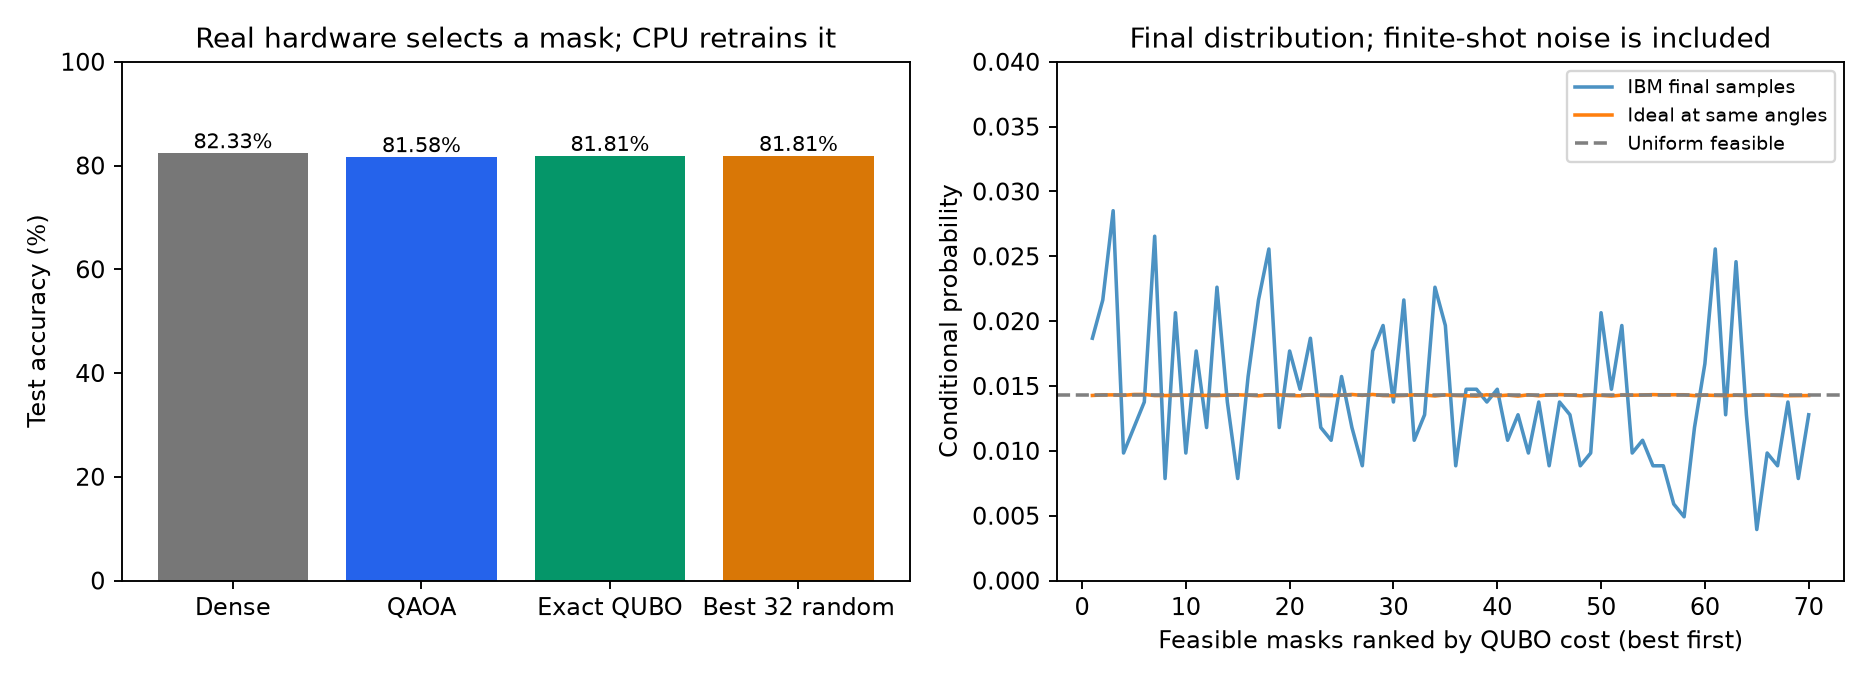

,stage,job ID,state,reported QPU seconds
0,replay,dbmi7bhkbkrc73cphr00,complete,2.0
1,step_1_plus,dbmi7q58mdtc73d80j30,complete,2.0
2,step_1_minus,dbmi8g674qds73dsb49g,complete,2.0
3,step_2_plus,dbmiakd8mdtc73d80o4g,complete,2.0
4,step_2_minus,dbmib3e74qds73dsb8gg,complete,2.0
5,step_3_plus,dbmibid8ft8s738utc60,complete,2.0
6,step_3_minus,dbmic1674qds73dsba40,complete,2.0
7,final,dbmidv674qds73dsbdvg,complete,3.0


In [8]:
hardware_path=BASE/'runs'/'hardware'/'state.json'
if not hardware_path.exists():
    print('HARDWARE STATUS: not started. No hardware result is being claimed.')
else:
    hardware=json.loads(hardware_path.read_text())
    print('Hardware phase:',hardware['phase'],'complete:',hardware['complete'])
    display(pd.DataFrame(hardware['history']))
    comparison_path=BASE/'runs'/'hardware'/'final_comparison.csv'
    if comparison_path.exists():
        display(pd.read_csv(comparison_path))
    if (BASE/'hardware_results.png').exists():
        display(Image(filename=str(BASE/'hardware_results.png')))
    ledger=json.loads((BASE/'runs'/'hardware'/'ledger.json').read_text())
    display(pd.DataFrame([{'stage':j['tag'],'job ID':j['job_id'],'state':j['state'],
                          'reported QPU seconds':j.get('reported_usage_seconds')} for j in ledger['jobs']]))


## 7. Present only what the evidence supports

1. Circuit correctness: exact encoding, parameter binding and bit-order checks.
2. Hardware execution: device/job IDs, transpiled circuits, counts and usage from actual jobs.
3. Useful pruning: validation retention, final test accuracy and retained parameters after rewinding.
4. Search effectiveness: compare against exact QUBO and matched best-of-random selection.
5. Speed: distinguish smaller-network inference speed from end-to-end pruning-search speed.

Current saved labels were collected before this hardware experiment. Their historical runtime
was not broken into every stage. This rehearsal and a future hardware run alone cannot establish
an exact end-to-end quantum speedup. The short optimizer budget, weak loss calibration and one
chosen initialization must be disclosed.

The helper files are `circuit_core.py` (circuit/scoring), `ibm_backend.py` (actual IBM jobs), and
`workflow.py` (optimization/retraining). See README.md for the executable commands.
